##  Onboarding Stage
This notebook demonstrates what happens when you call `scripts/extract_template_descriptors.py`.

Make sure you have completed the setup instructions in `README.md` before running this notebook. Run the notebook from the cnos25 repo root directory.

In [1]:
import os
import logging
import hydra
from src.model.descriptor.template_extraction import DinoTemplateExtraction
from src.utils.imgproc import pilImageRow

### Loading the configuration from `extract_templates.yaml`
This is done automatically when you call `scripts/extract_template_descriptors.py`.

In [2]:
config_dir = os.path.abspath("./configs")

with hydra.initialize_config_dir(config_dir=config_dir, version_base=None):
    cfg = hydra.compose(config_name="extract_templates", overrides=["dataset_name=hopev2"])  # handal onboarding data not downloaded yet

### Instantiation of dataloader and template_extraction object

In [3]:
# Instantiate the reference dataloader (the one that provides the crops from the onboarding images)
ref_dataloader = hydra.utils.instantiate(cfg.data.reference_dataloader)

In [4]:
# Instantiate the object that handles the template descriptor extraction and saving
template_extraction = DinoTemplateExtraction(descriptor_model=cfg.descriptor_model,
                                            ref_dataloader=ref_dataloader,
                                            obj_names=cfg.data.datasets[cfg.dataset_name].obj_names,
                                            dataset_name=cfg.dataset_name)

/home/vincirist/1_repos/cnos25/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Extract the cropped and masked template images for each object
This may take a while, so reduce the number of images per object to 6 only

In [5]:
ref_dataloader.num_imgs_per_obj = 6

And start extraction...

In [6]:
template_extraction.set_ref_images()

100%|██████████| 3/3 [00:00<00:00, 18.96it/s]


### The extracted crops are stored in a dict named ref_images:

In [7]:
template_extraction.ref_images.keys()

dict_keys(['AlphabetSoup', 'BBQSauce', 'Butter', 'Cherries', 'ChocolatePudding', 'Cookies', 'Corn', 'CreamCheese', 'GranolaBars', 'GreenBeans', 'Ketchup', 'Macaroni&Cheese', 'Mayo', 'Milk', 'Mushrooms', 'Mustard', 'OrangeJuice', 'Parmesan', 'Peaches', 'Peas&Carrots', 'Pineapple', 'Popcorn', 'Raisins', 'SaladDressing', 'Spaghetti', 'TomatoSauce', 'Tuna', 'Yogurt'])

### Let's view them!

AlphabetSoup                BBQSauce


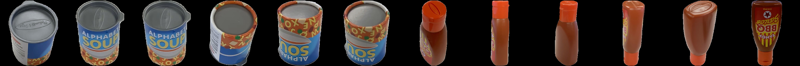

Butter                Cherries


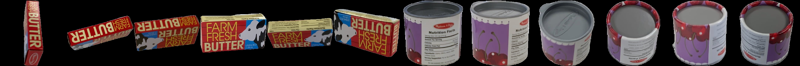

ChocolatePudding                Cookies


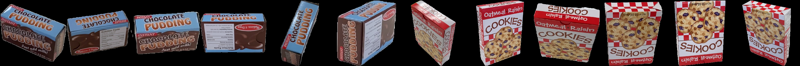

Corn                CreamCheese


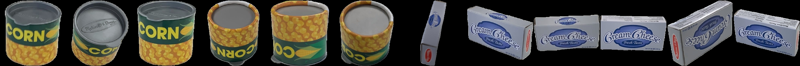

GranolaBars                GreenBeans


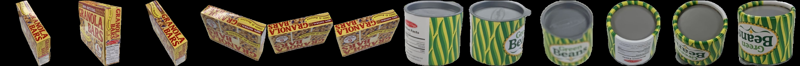

Ketchup                Macaroni&Cheese


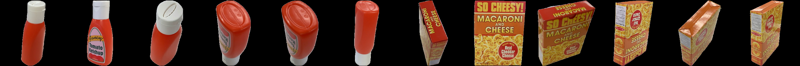

Mayo                Milk


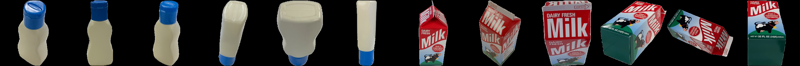

Mushrooms                Mustard


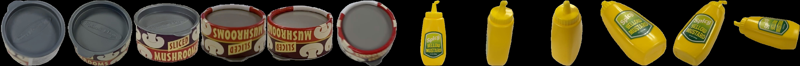

OrangeJuice                Parmesan


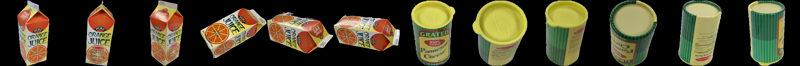

Peaches                Peas&Carrots


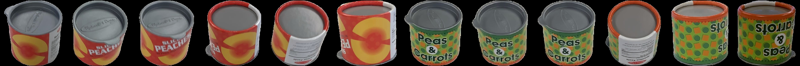

Pineapple                Popcorn


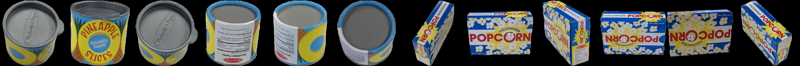

Raisins                SaladDressing


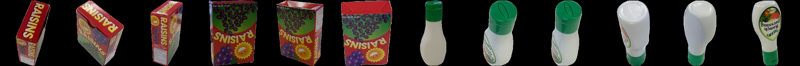

Spaghetti                TomatoSauce


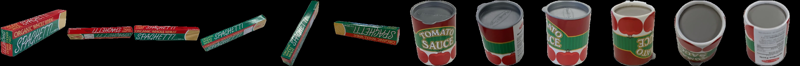

Tuna                Yogurt


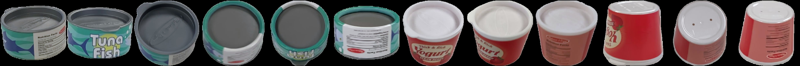

In [8]:
def overview():
    keys = list(template_extraction.ref_images.keys())
    for i in range(len(keys)):
        if i%2!=0:continue
        _next=[]
        if i+1 < len(keys):
            print(keys[i], '              ', keys[i+1])
            _next = template_extraction.ref_images[keys[i+1]]
        else:  print(keys[i])
        display(pilImageRow(*template_extraction.ref_images[keys[i]],*_next))

overview()

Nice.

### Forward each crop through dinov3 to get their descriptors:

In [9]:
# Forward pass through the descriptor model to get descriptors
template_extraction.calc_ref_embs()

Computing template descriptors ...: 100%|██████████| 28/28 [00:00<00:00, 34.75it/s]


They're stored in ref_descriptors. Let's view the first 4 of them:

In [10]:
{(i,key,descriptor.shape) for i, (key,descriptor) in enumerate(template_extraction.ref_descriptors.items()) if i < 4}

{(0, 'x_norm_clstoken_AlphabetSoup', torch.Size([6, 1024])),
 (1, 'x_norm_patchtokens_AlphabetSoup', torch.Size([6, 256, 1024])),
 (2, 'x_norm_clstoken_BBQSauce', torch.Size([6, 1024])),
 (3, 'x_norm_patchtokens_BBQSauce', torch.Size([6, 256, 1024]))}

### We have the template descriptors. We're done!
But let's don't forget to save them:

In [11]:
 # Save descriptors dict to a .pt
template_extraction.save(out_file='demo.pt', overwrite=True)

100%|██████████| 56/56 [00:00<00:00, 745.83it/s]


### And finally check if we've done alright

In [12]:
logging.basicConfig(level=logging.DEBUG, force=True)

template_extraction.check_saved('demo.pt')

INFO:root:opening /home/vincirist/1_repos/cnos25/data/hopev2/onboarding_static/descriptors/demo.pt of size 220.9M
INFO:root:entries in saved file: {'template_embeds': 56, 'template_imgs': 28, 'template_masks': 28}
